## Abstract

Transformers trained on planetary orbits learn a Newtonian world model at short context and a Keplerian one at long context. We apply Equivalent Linear Mapping to decompose *how* the short-context model builds a Newtonian gravitational force from two past positions.

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

Liu et al. (2025) showed that transformers trained to predict planetary motion learn qualitatively different *world models* depending on context length — a local, force-based **Newtonian** model at short context and a global, geometry-based **Keplerian** model at long context — and detected this with linear probes (*what* is encoded). Here we ask *how* the model computes: we apply **Equivalent Linear Mapping (ELM)** to rewrite the trained transformer as an exact per-token linear map and read the gravitational force directly out of its Jacobian. This intro section establishes the two ingredients the rest of the pub builds on: (1) the ELM decomposition is *exact*, so its per-token attributions are trustworthy, and (2) our checkpoints reproduce the Newton↔Kepler phase transition. The primary audience is interpretability and world-model researchers.


In [1]:
#| code-fold: true
#| output: false
import io
import os
import contextlib

import numpy as np
import torch
import matplotlib.pyplot as plt

from analysis.model import load_from_checkpoint

torch.set_default_dtype(torch.float64)   # ELM reconstruction is exact only at float64

CHECKPOINT_DIR = './checkpoints/kepler_cv_blocksize_elm'
DATA_DIR       = 'data_cv'
NUM_TRAJ, NOISE_SCALE, SEED = 10000, 0.1, 0
CKPT_BS2   = f'{CHECKPOINT_DIR}/model_block_size_2_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'
CKPT_BS100 = f'{CHECKPOINT_DIR}/model_block_size_100_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'

with contextlib.redirect_stdout(io.StringIO()):
    model_bs2,   _ = load_from_checkpoint(CKPT_BS2,   device='cpu'); model_bs2.eval()
    model_bs100, _ = load_from_checkpoint(CKPT_BS100, device='cpu'); model_bs100.eval()


## Verifying the ELM decomposition

**Equivalent Linear Mapping (ELM)** rewrites the transformer as a *pointwise-linear*
map at a chosen input $x^*$ by detaching three input-dependent nonlinearities from the
gradient computation:

- **LayerNorm denominator** — the RMS normalisation constant $\sigma(x^*)$ is frozen,
  so the gradient sees only the linear numerator $x / \sigma(x^*)$. Crucially the
  mean-centering $(x - \bar{x})$ is *kept* in the gradient path because it is a linear
  operation (multiplication by the centering matrix $C = I - \mathbf{1}\mathbf{1}^\top/d$);
  detaching the mean would inject a spurious constant into the reconstruction.
- **SiLU gate** — $\text{SiLU}(x) = x \cdot \sigma(x)$ is linearised as
  $x \cdot \sigma(x^*)$, freezing the sigmoid factor so only the linear $x$ carries
  gradient.
- **Attention weights** — both the query $Q$ and key $K$ matrices are detached before
  the score computation, freezing the full attention weight matrix $A(x^*)$. The gradient
  flows only through the value path $V = W_V x$, making attention linear in the input.
  Detaching only $\text{softmax}(QK^\top)$ would be insufficient because $Q$ and $K$
  themselves depend on $x$.

With these three detachments the map $x \to y$ becomes degree-1 homogeneous at $x^*$,
and the detached Jacobians satisfy $y^* = \sum_t J_t(x^*)\, x_t^*$ exactly.

**Embedding-level decomposition.** A plain-text transformer has additive positional
embeddings $h_t = W_{\rm in} x_t + \mathrm{wpe}[t]$, making the raw-input map
$x \to y$ affine rather than homogeneous — differentiating w.r.t. $x$ leaves
$\mathrm{wpe}[t]$ as an unaccounted constant. We therefore differentiate
*downstream of the embedding sum*, treating $h_t$ as the variable. Because the
downstream map $h \to y$ is degree-1 homogeneous after ELM detachment, it
reconstructs exactly, and the chain rule through the linear embedding
$W_{\rm in}$ gives a clean content/positional split:

$$y^* = \underbrace{\sum_t J_{h,t}\, W_{\rm in}\, x_t}_{\text{content}} +
        \underbrace{\sum_t J_{h,t}\, \mathrm{wpe}[t]}_{\text{positional}}$$

where $J_{x,t} = J_{h,t}\, W_{\rm in}$ is the $2\times 2$ block in $(x,y)$ input
space that we compare to the Verlet targets $J_{\rm recent} \sim 2I$,
$J_{\rm prev} \sim -I$.

**Verification.** @fig-elm-recon plots the model's forward output against the
ELM reconstruction (content + positional) for the last output token, at both
context lengths. The points lie on the identity line with relative error
$\sim\!10^{-9}$ — the Jacobian is an exact linear stand-in for the model at
$x^*$, so the per-token attributions used throughout this pub are trustworthy.

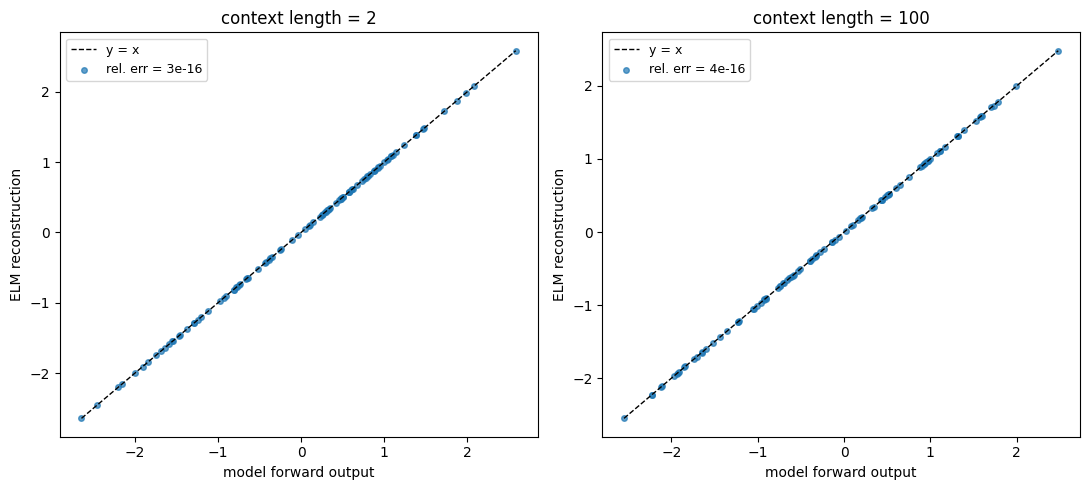

In [2]:
#| label: fig-elm-recon
#| fig-cap: "ELM reconstruction vs. model forward output for the last token, at context length 2 and 100. Points on the identity line (relative error ~1e-9) confirm the detached Jacobian is an exact linear decomposition of the model."
#| code-fold: true
from analysis.elm import reconstruction_scatter

mv_2,   ev_2   = reconstruction_scatter(model_bs2,   2,   n_windows=50, seed=SEED, offset=NUM_TRAJ)
mv_100, ev_100 = reconstruction_scatter(model_bs100, 100, n_windows=50, seed=SEED, offset=NUM_TRAJ)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, mv, ev, label in [(axes[0], mv_2,   ev_2,   'context length = 2'),
                          (axes[1], mv_100, ev_100, 'context length = 100')]:
    err = np.linalg.norm(ev - mv) / np.linalg.norm(mv)
    lo, hi = float(min(mv.min(), ev.min())), float(max(mv.max(), ev.max()))
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x')
    ax.scatter(mv, ev, s=16, c='tab:blue', alpha=0.7, label=f'rel. err = {err:.0e}')
    ax.set_xlabel('model forward output'); ax.set_ylabel('ELM reconstruction')
    ax.set_title(label); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()


## Two world models: the Newton–Kepler phase transition

We first confirm *what* each model has learned, following Liu et al.'s linear-probing approach: for a target variable (e.g. a force component $F_x$, or a Laplace–Runge–Lenz component $A_x$) we fit a linear direction in the hidden state and report the best-layer $R^2$. @fig-phase-transition shows the result. At **context length 2** the model linearly encodes the Newtonian force variables ($F$, $F_x$, $F_y$); at **context length 100** it instead encodes the Keplerian orbital parameters (semi-axes $a$, $b$ and the LRL vector $A_x$, $A_y$). This is the phase transition Liu et al. identified, and our checkpoints reproduce it (consistent within run-to-run variance). The rest of the pub asks *how* the short-context model implements its Newtonian force.


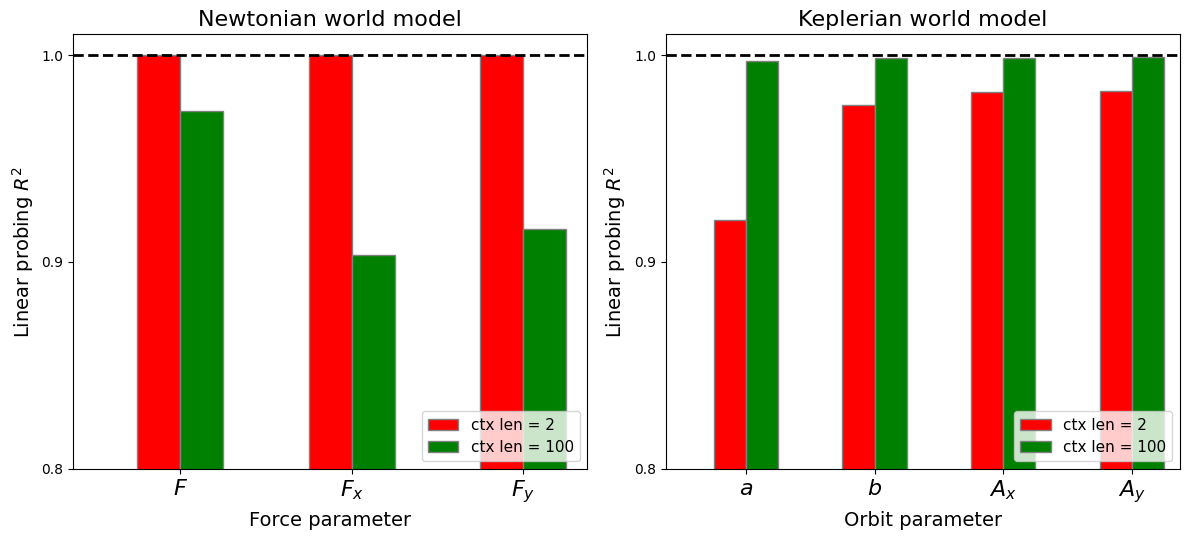

In [12]:
#| label: fig-phase-transition
#| fig-cap: "Best-layer, last-position linear-probing R² for Newtonian force variables (left) and Keplerian orbital parameters (right), at context length 2 vs 100. Short context encodes forces; long context encodes orbital geometry — consistent with Liu et al. within run-to-run variance."
#| code-fold: true
from analysis.data import load_trajectories, load_orbital_params
from analysis.probing import probe_model, best_r2

with contextlib.redirect_stdout(io.StringIO()):
    trajs_all    = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=2 * NUM_TRAJ))
    o_params_all = load_orbital_params(DATA_DIR, num_trajectories_needed=2 * NUM_TRAJ)
    trajs, o_params = trajs_all[NUM_TRAJ:], o_params_all[NUM_TRAJ:]   # held-out test split
    newton_2,   kepler_2   = probe_model(model_bs2,   trajs, o_params, 2,   n_probe=1000, seed=SEED)
    newton_100, kepler_100 = probe_model(model_bs100, trajs, o_params, 100, n_probe=1000, seed=SEED)

NEWTON = [('F_magnitude', r'$F$'), ('Fx', r'$F_x$'), ('Fy', r'$F_y$')]
KEPLER = [('a', r'$a$'), ('b', r'$b$'), ('LRL_x', r'$A_x$'), ('LRL_y', r'$A_y$')]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, xlabel, items, p2, p100) in zip(axes, [
        ('Newtonian world model', 'Force parameter', NEWTON, newton_2, newton_100),
        ('Keplerian world model', 'Orbit parameter', KEPLER, kepler_2, kepler_100)]):
    targets = [t for t, _ in items]; ticklab = [l for _, l in items]
    r2_2   = [best_r2(p2,   t) for t in targets]
    r2_100 = [best_r2(p100, t) for t in targets]
    bw = 0.25; br1 = np.arange(len(targets))
    b1 = ax.bar(br1,      r2_2,   bw, color='r', edgecolor='grey', label='ctx len = 2')
    b2 = ax.bar(br1 + bw, r2_100, bw, color='g', edgecolor='grey', label='ctx len = 100')
    ax.plot([-0.5, len(targets) - 0.5], [1, 1], '--', color='black', lw=2)
    ax.set_xlim(-0.5, len(targets) - 0.5); ax.set_ylim(0.8, 1.01); ax.set_yticks([0.8, 0.9, 1.0])
    ax.set_xticks(br1 + 0.5 * bw); ax.set_xticklabels(ticklab, fontsize=16)
    ax.set_xlabel(xlabel, fontsize=14); ax.set_ylabel(r'Linear probing $R^2$', fontsize=14)
    ax.set_title(title, fontsize=16); ax.legend(handles=[b1, b2], fontsize=11, loc='lower right')
fig.tight_layout(); plt.show()


## Inside the short-context model

The probes told us the short-context (context length 2) model linearly encodes Newtonian force variables. But *encoding* a quantity is not the same as *computing with* it. With ELM we can read out the actual computation — how the model turns the two positions it sees, $\mathbf r_{t-1}$ and $\mathbf r_t$, into its prediction $\hat{\mathbf r}_{t+1}$.

A textbook second-order integrator of gravity — Störmer–Verlet — would do
$$\hat{\mathbf r}_{t+1} = 2\,\mathbf r_t - \mathbf r_{t-1} - \Delta t^2\,\nabla\phi(\mathbf r_t),$$
i.e. per-token isotropic coefficients $(c_{\text{prev}}, c_{\text{recent}}) = (-1, 2)$ plus a small gravitational correction. That is our baseline: a Newtonian force integrator should sit near the **Verlet point** $(-1, 2)$. Here $c_s = \mathrm{tr}(J_s)/D$ is the isotropic part of each per-token Jacobian block — the scalar by which position $s$ is scaled into the prediction.


In [4]:
#| code-fold: true
#| output: false
# Mechanistic analysis of the short-context (noise=0.1) model. Reuses the model and
# constants loaded in the intro setup; only adds the analysis helpers.
from analysis import elm as NT
from analysis.data import load_trajectories

model = model_bs2                 # the bs=2, noise=0.1 model from the intro

BLOCK_SIZE    = 2
N_WINDOWS     = 200               # Jacobian-based analyses (expensive)
N_WINDOWS_BEH = 4000              # behavioural analyses (cheap forward passes)
SPLIT  = 'test'
OFFSET = 0 if SPLIT == 'train' else NUM_TRAJ   # 50/50 train/test split, by trajectory

def load_split_trajectories(n, data_dir=DATA_DIR, offset=None):
    offset = OFFSET if offset is None else offset
    with contextlib.redirect_stdout(io.StringIO()):
        trajs = np.asarray(load_trajectories(data_dir, num_trajectories_needed=offset + n))
    return trajs[offset:offset + n]


In [5]:
#| code-fold: true
#| output: false
# Per-token Jacobian blocks over N_WINDOWS real-orbit windows (slow; ~1-2 min).
all_blocks, coeffs, recon_err_max = NT.collect(model, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]
D = all_blocks.shape[-1]


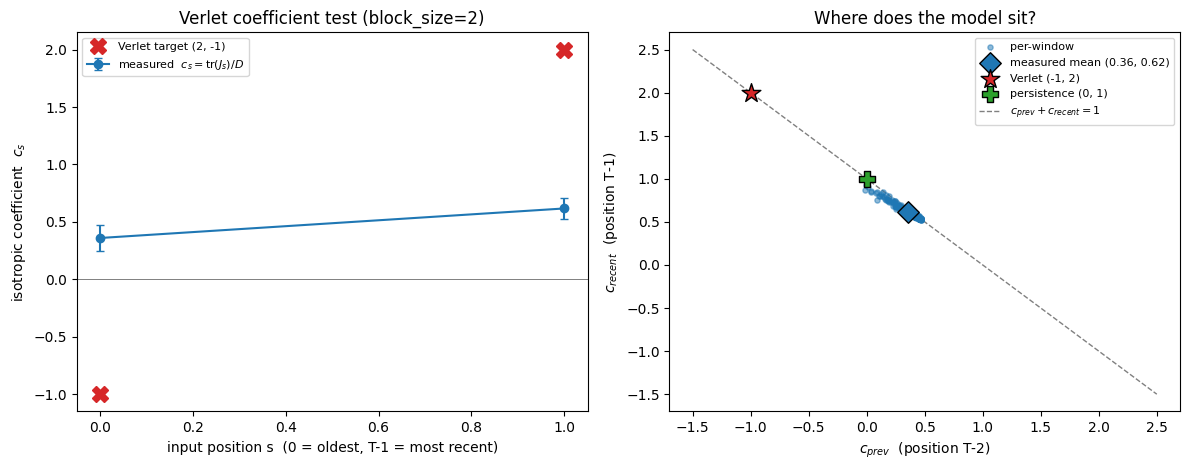

In [6]:
#| label: fig-verlet-coeff
#| fig-cap: "Isotropic Jacobian coefficients of the noisy bs=2 model. Left: measured c_s per input position vs. the Verlet target (2, -1). Right: the model in (c_prev, c_recent) space — it sits on the persistence line (sum = 1) near (0.36, 0.62), far from the Verlet point (-1, 2)."
#| code-fold: true
positions = np.arange(T)
c_mean, c_std = coeffs.mean(0), coeffs.std(0)

target = np.zeros(T); target[T-1] = 2.0; target[T-2] = -1.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ax = axes[0]
ax.axhline(0, color='gray', lw=0.7)
ax.errorbar(positions, c_mean, yerr=c_std, fmt='-o', color='tab:blue', capsize=3,
            label=r'measured  $c_s=\mathrm{tr}(J_s)/D$')
ax.plot(positions, target, 'X', color='tab:red', ms=12, label='Verlet target (2, -1)')
ax.set_xlabel('input position s  (0 = oldest, T-1 = most recent)')
ax.set_ylabel(r'isotropic coefficient  $c_s$')
ax.set_title(f'Verlet coefficient test (block_size={BLOCK_SIZE})'); ax.legend(fontsize=8)

ax = axes[1]
c_prev, c_recent = coeffs[:, T-2], coeffs[:, T-1]
ax.scatter(c_prev, c_recent, s=14, alpha=0.5, color='tab:blue', label='per-window', zorder=2)
ax.scatter([c_prev.mean()], [c_recent.mean()], s=120, marker='D', color='tab:blue', edgecolor='k',
           label=f'measured mean ({c_prev.mean():.2f}, {c_recent.mean():.2f})', zorder=4)
ax.scatter([-1], [2], s=200, marker='*', color='tab:red', edgecolor='k', label='Verlet (-1, 2)', zorder=5)
ax.scatter([0], [1], s=120, marker='P', color='tab:green', edgecolor='k', label='persistence (0, 1)', zorder=4)
lo = min(-1.5, float(c_prev.min())); hi = max(2.5, float(c_recent.max()))
xs = np.linspace(lo, hi, 50)
ax.plot(xs, 1 - xs, ls='--', color='gray', lw=1, label=r'$c_{prev}+c_{recent}=1$', zorder=1)
ax.set_xlabel(r'$c_{prev}$  (position T-2)'); ax.set_ylabel(r'$c_{recent}$  (position T-1)')
ax.set_title('Where does the model sit?'); ax.legend(fontsize=8, loc='best')

fig.tight_layout(); plt.show()


@fig-verlet-coeff shows the model does **not** sit at the Verlet point. Its isotropic coefficients are $(c_{\text{prev}}, c_{\text{recent}}) \approx (0.36, 0.62)$ — they sum to $\approx 1$ (on the dashed *persistence* line) but land nowhere near $(-1, 2)$. A force integrator *extrapolates forward* along the velocity (overshooting $\mathbf r_t$, hence weights $2, -1$); this model instead forms a **positive-weighted blend** of its two inputs. So the noise-robust short-context model is not doing textbook Newtonian integration.

What it *is* doing is clearer from the whole Jacobian block, not just its scale. @fig-jacobian-rotation shows the averaged per-token blocks: both are, to a good approximation, **scaled rotation matrices** — equal diagonals and equal-and-opposite off-diagonals, i.e. $J_s \approx c_s\,R(\theta_s)$. The model does not push $\mathbf r_t$ forward; it *turns* it.


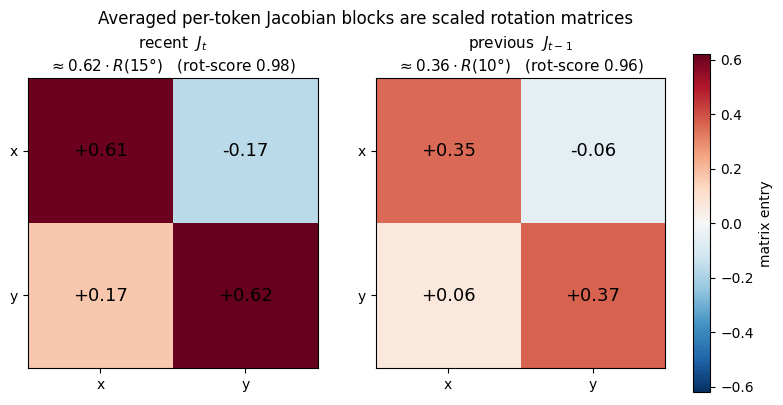

In [7]:
#| label: fig-jacobian-rotation
#| fig-cap: "Averaged per-token Jacobian blocks of the noisy bs=2 model. Both are scaled rotation matrices (equal diagonals, equal-and-opposite off-diagonals): J_recent ~ 0.62 R(15 deg), J_prev ~ 0.36 R(10 deg). Per-window rotation-score ~ 0.98 (the mean is faithful because every orbit shares angular-momentum sign)."
#| code-fold: true
from analysis.elm import rotation_decompose

mean_recent = all_blocks[:, T-1].mean(0)
mean_prev   = all_blocks[:, T-2].mean(0)
_, _, _, score_recent = rotation_decompose(all_blocks[:, T-1])
_, _, _, score_prev   = rotation_decompose(all_blocks[:, T-2])
sc_r, _, ang_r, _ = rotation_decompose(mean_recent)
sc_p, _, ang_p, _ = rotation_decompose(mean_prev)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
vmax = max(abs(mean_recent).max(), abs(mean_prev).max())
for ax, M, name, sc, ang, sco in [
        (axes[0], mean_recent, r'recent  $J_{t}$',     sc_r, ang_r, score_recent.mean()),
        (axes[1], mean_prev,   r'previous  $J_{t-1}$', sc_p, ang_p, score_prev.mean())]:
    im = ax.imshow(M, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=13)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['x', 'y']); ax.set_yticklabels(['x', 'y'])
    ax.set_title(f'{name}\n' + rf'$\approx {float(sc):.2f}\cdot R({float(ang):.0f}\degree)$   (rot-score {sco:.2f})', fontsize=11)
fig.colorbar(im, ax=list(axes), fraction=0.046, pad=0.04, label='matrix entry')
fig.suptitle('Averaged per-token Jacobian blocks are scaled rotation matrices', fontsize=12)
plt.show()


Per window the rotation structure is even cleaner (rotation-score $\approx 0.98$); the *average* is faithful here only because every orbit shares angular-momentum sign, so the rotations reinforce rather than cancel. If this Jacobian rotation is genuinely the model's mechanism, the angle it predicts should match the model's *behavioral* rotation — the angle by which the prediction turns $\mathbf r_t$:


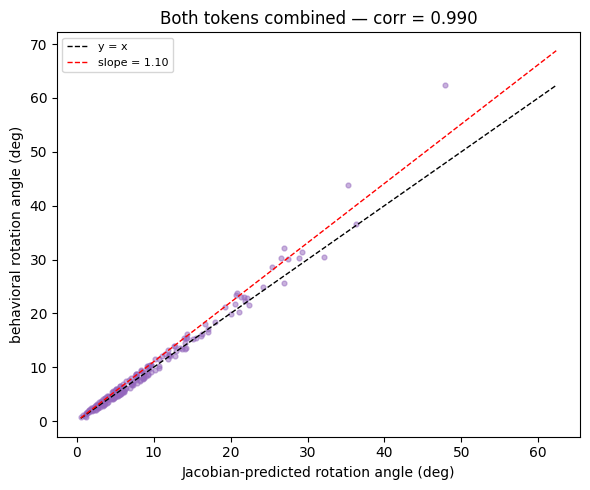

In [8]:
#| label: fig-jac-vs-behavioral
#| fig-cap: "Jacobian-predicted rotation angle (combining both content blocks) vs. the model's behavioral rotation angle (r_t to the prediction), over test-set windows. The tight agreement confirms the ELM decomposition captures the model's rotation mechanism."
#| code-fold: true
from analysis.elm import jacobian_vs_behavioral_angle

trajs_c = load_split_trajectories(500)
ang_jac, ang_beh, corr_jac, slope_jac = jacobian_vs_behavioral_angle(
    model, trajs_c, BLOCK_SIZE, N_WINDOWS, seed=SEED)

fig, ax = plt.subplots(figsize=(6, 5))
lo = float(min(ang_jac.min(), ang_beh.min())); hi = float(max(ang_jac.max(), ang_beh.max()))
xs = np.linspace(lo, hi, 100)
ax.scatter(ang_jac, ang_beh, s=12, alpha=0.5, color='tab:purple')
ax.plot(xs, xs, 'k--', lw=1, label='y = x')
ax.plot(xs, slope_jac * xs, 'r--', lw=1, label=f'slope = {slope_jac:.2f}')
ax.set_xlabel('Jacobian-predicted rotation angle (deg)')
ax.set_ylabel('behavioral rotation angle (deg)')
ax.set_title(f'Both tokens combined — corr = {corr_jac:.3f}')
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()


It does. @fig-jac-vs-behavioral compares the rotation angle predicted by combining the two Jacobian blocks against the model's *behavioral* rotation (the actual signed angle from $\mathbf r_t$ to $\hat{\mathbf r}_{t+1}$); the two track each other tightly (correlation shown in the panel). So the linear decomposition captures the mechanism — which lets us ask the sharper questions in the sections that follow: *what does this rotation depend on, and how is it built from the Jacobian's channels?*


### What the rotation depends on

The model *rotates* $\mathbf r_t$ — but what sets the angle? Kepler's second law says a real orbit sweeps area at a constant rate, so its per-step angle is $\Delta\theta = L_z\,\Delta t / r^2$: it grows like $1/r^2$ **and** scales with the orbit's angular momentum $L_z$. We compare the model's per-step rotation against both, and against the radius changes a real orbit undergoes.


In [9]:
#| code-fold: true
#| output: false
# Behavioural rotation statistics over many cheap forward passes.
behav = NT.rotation_behavioral(model, BLOCK_SIZE, N_WINDOWS_BEH, seed=SEED, offset=OFFSET)


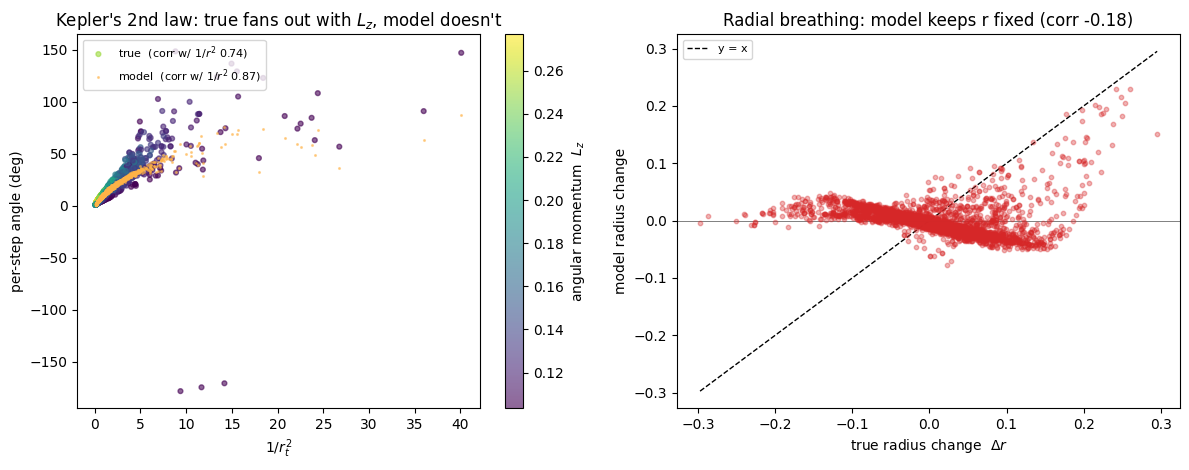

In [10]:
#| label: fig-kepler2
#| fig-cap: "Left: per-step rotation angle vs 1/r^2. The true orbit's angle (coloured by angular momentum L_z) fans out with L_z per Kepler's 2nd law, whereas the model's angle (orange) is a tight function of 1/r^2 alone — it ignores L_z. Right: the true per-step radius change vs the model's; the model keeps the radius almost fixed, ignoring the orbit's radial breathing."
#| code-fold: true
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left — Kepler's 2nd law: per-step angle vs 1/r^2
ax = axes[0]
Lz, inv_r2 = behav['Lz'], behav['inv_r2']
at, am = np.degrees(behav['ang_true']), np.degrees(behav['ang_model'])
vlo, vhi = float(np.nanpercentile(Lz, 2)), float(np.nanpercentile(Lz, 98))
sc = ax.scatter(inv_r2, at, s=12, alpha=0.6, c=Lz, cmap='viridis', vmin=vlo, vmax=vhi,
                label=f"true  (corr w/ $1/r^2$ {behav['kepler2_corr_true']:.2f})")
ax.scatter(inv_r2, am, s=6, alpha=0.5, color='#FFB347', marker='.',
           label=f"model  (corr w/ $1/r^2$ {behav['kepler2_corr_model']:.2f})")
cb = fig.colorbar(sc, ax=ax); cb.set_label(r'angular momentum  $L_z$')
ax.set_xlabel(r'$1/r_t^2$'); ax.set_ylabel('per-step angle (deg)')
ax.set_title(r"Kepler's 2nd law: true fans out with $L_z$, model doesn't")
ax.legend(fontsize=8, loc='upper left')

# Right — radial breathing
ax = axes[1]
dtr, dmr = behav['dr_true'], behav['dr_model']
lo, hi = float(min(dtr.min(), dmr.min())), float(max(dtr.max(), dmr.max()))
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.axhline(0, color='gray', lw=0.7, zorder=1)
ax.scatter(dtr, dmr, s=10, alpha=0.35, color='tab:red', zorder=2)
ax.set_xlabel(r'true radius change  $\Delta r$'); ax.set_ylabel(r'model radius change')
ax.set_title(f"Radial breathing: model keeps r fixed (corr {behav['dr_corr']:.2f})")
ax.legend(fontsize=8)

fig.tight_layout(); plt.show()


Two things stand out in @fig-kepler2. The model's rotation angle **does** grow like $1/r^2$ — it speeds up near the sun — but unlike the true orbit it is a *single tight curve*: it **ignores angular momentum** (the orange points show no vertical spread, while the true points fan out by colour). And on the right, the model barely changes the radius step-to-step — it **ignores the orbit's radial breathing**, keeping the planet on a circle.

Together these say the model isn't tracking the real orbit; it treats each step as if the planet were on a *local circular orbit* of the current radius. A circular orbit at radius $r$ sweeps $\Delta\theta = \Delta t / r^{3/2}$ per step (with $GM=1$). If that is the heuristic, the model's rotation should match this curve:


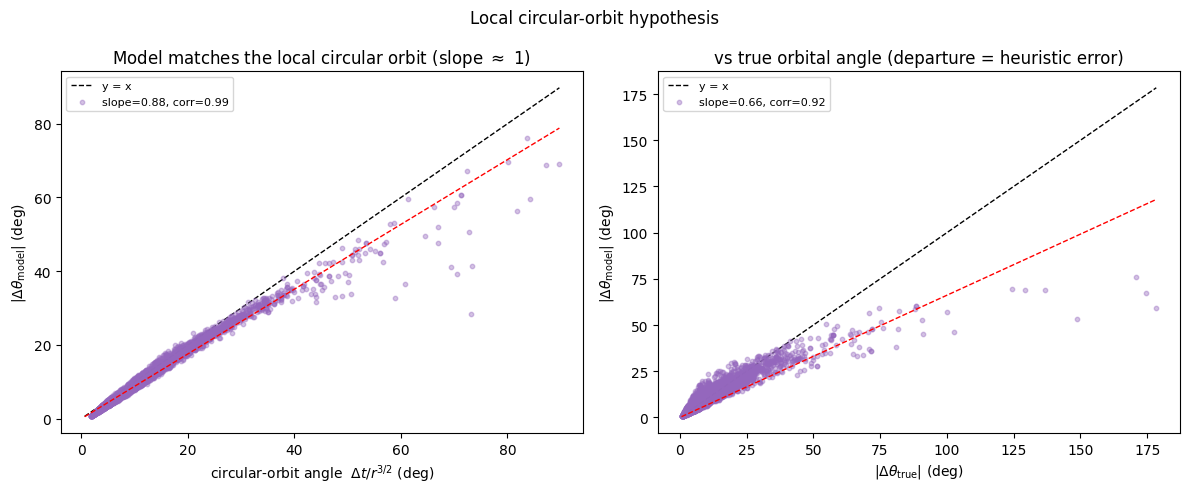

In [11]:
#| label: fig-circular
#| fig-cap: "Left: model per-step rotation angle vs the angle a circular orbit of the same radius sweeps (dt / r^{3/2}); slope ~ 1 shows the model applies the local-circular-orbit rotation. Right: model angle vs the true orbital angle; departures from y=x are the heuristic's error on eccentric orbits. (Windows with a circular prediction > 90 deg are dropped.)"
#| code-fold: true
DT = 0.2
r_t          = behav['inv_r2'] ** (-0.5)
ang_circular = np.degrees(DT / r_t**1.5)
am_abs, at_abs = np.abs(np.degrees(behav['ang_model'])), np.abs(np.degrees(behav['ang_true']))

mask = ang_circular < 90.0
ang_c_m, am_m, at_m = ang_circular[mask], am_abs[mask], at_abs[mask]
corr_m,   slope_m   = np.corrcoef(ang_c_m, am_m)[0, 1], np.polyfit(ang_c_m, am_m, 1)[0]
corr_beh, slope_beh = np.corrcoef(at_m,   am_m)[0, 1], np.polyfit(at_m,   am_m, 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
lo, hi = float(min(ang_c_m.min(), am_m.min())), float(max(ang_c_m.max(), am_m.max()))
xs = np.linspace(lo, hi, 100)
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(ang_c_m, am_m, s=10, alpha=0.4, color='tab:purple', zorder=2,
           label=f'slope={slope_m:.2f}, corr={corr_m:.2f}')
ax.plot(xs, slope_m * xs, 'r--', lw=1)
ax.set_xlabel(r'circular-orbit angle  $\Delta t / r^{3/2}$ (deg)')
ax.set_ylabel(r'$|\Delta\theta_{\rm model}|$ (deg)')
ax.set_title(r'Model matches the local circular orbit (slope $\approx$ 1)')
ax.legend(fontsize=8)

ax = axes[1]
lo2, hi2 = float(min(at_m.min(), am_m.min())), float(max(at_m.max(), am_m.max()))
xs2 = np.linspace(lo2, hi2, 100)
ax.plot([lo2, hi2], [lo2, hi2], 'k--', lw=1, label='y = x', zorder=1)
ax.scatter(at_m, am_m, s=10, alpha=0.4, color='tab:purple', zorder=2,
           label=f'slope={slope_beh:.2f}, corr={corr_beh:.2f}')
ax.plot(xs2, slope_beh * xs2, 'r--', lw=1)
ax.set_xlabel(r'$|\Delta\theta_{\rm true}|$ (deg)')
ax.set_ylabel(r'$|\Delta\theta_{\rm model}|$ (deg)')
ax.set_title('vs true orbital angle (departure = heuristic error)')
ax.legend(fontsize=8)

fig.suptitle('Local circular-orbit hypothesis', fontsize=12)
fig.tight_layout(); plt.show()


### The noisy short-context model runs a local circular-orbit heuristic

@fig-circular confirms it: the model's rotation angle tracks the circular-orbit prediction $\Delta t / r^{3/2}$ with slope $\approx 1$ (left), and departs from the *true* angle only where real orbits deviate from circular (right).

So the noise-robust short-context model has **not** learned Newtonian gravity. It has learned a **local circular-orbit heuristic**: rotate the most recent position by the angle a circular orbit of that radius would sweep, and hold the radius fixed. This is a smooth, noise-tolerant approximation — it captures the $1/r^2$ angular speed-up but discards angular momentum and radial dynamics, which is exactly why it degrades on eccentric orbits. The genuine Newtonian mechanism only emerges once we remove the training noise — the subject of the next section.
